In [5]:
import numpy as np
import pandas as pd

#getting path for dataset
import os
for dirname, _, filenames in os.walk('/Users/partha/AI_ML_Projects/SMS-Spam-Classifier-ML/datasets'):
    for f in filenames:
        print (os.path.join(dirname, f))


/Users/partha/AI_ML_Projects/SMS-Spam-Classifier-ML/datasets/spam.csv


In [7]:
#read the csv file
# /Users/partha/AI_ML_Projects/SMS-Spam-Classifier-ML/datasets/spam.csv
df = pd.read_csv('/Users/partha/AI_ML_Projects/SMS-Spam-Classifier-ML/datasets/spam.csv',encoding='latin-1')

df.head()
# df.shape # (5572, 5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [8]:
#Data Cleaning

#dropping the last 3 columns as they are not required
df.drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], inplace=True, axis=1)

#renaming the columns
df.rename(columns={'v1':'target', 'v2':'text'}, inplace=True)

#lets label the target column as 0 and 1 for ham and spam respectively
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
df['target']=encoder.fit_transform(df['target'])

df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [9]:
#lets check for missing values
df.isnull().sum()

target    0
text      0
dtype: int64

In [10]:
#check for duplicate values
print(df.duplicated().sum()) # came as 403 duplicate values

df = df.drop_duplicates(keep='first')
print(df.duplicated().sum()) # came as 0 duplicate values

403
0


In [11]:
#Exploratory Data Analysis (EDA)

df['target'].value_counts() #  ham = 4516, spam = 653

target
0    4516
1     653
Name: count, dtype: int64

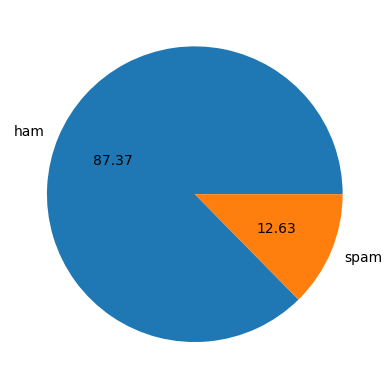

In [12]:
import matplotlib.pyplot as plt

plt.pie(df['target'].value_counts(), labels=['ham','spam'],autopct="%0.2f")
plt.show()

In [13]:
!pip install nltk

In [14]:
#data is imbalanced

import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to /Users/partha/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [15]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/partha/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [16]:
#num of characters
df['num_characters']=df['text'].apply(len)

#num of words
df['num_words']=df['text'].apply(lambda x:len(nltk.word_tokenize(x)))

#num of sentences
df['num_sentences']=df['text'].apply(lambda x:len(nltk.sent_tokenize(x)))

In [17]:
df.head()

,target,text,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [18]:
df[['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,1.965564
std,58.236293,13.324758,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [19]:
#ham
df[df['target']==0][['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [20]:
#spam
df[df['target']==1][['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


In [21]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/partha/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [22]:
#data preprocessing
# - lowercase
# - tokenization
# - removing special characters
# - removing stop words and punctuation
# - stemming
import nltk
import string

from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

ps = PorterStemmer()

def transform_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)

    #removes special characters
    y=[]
    for i in text:
        if i.isalnum():
            y.append(i)

    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)

    text = y[:]
    y.clear()

    for i in text:
        y.append(ps.stem(i))

    return " ".join(y)

In [23]:
transform_text(df['text'][10])

"i gon na be home soon and i do want to talk about thi stuff anymor tonight k i cri enough today 'm gon na home soon n't want talk stuff anymor tonight k 've cri enough today"

In [24]:
df['transformed_text']=df['text'].apply(transform_text)

In [25]:
df.head()

,target,text,num_characters,num_words,num_sentences,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go until jurong point crazi avail onli in bugi...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni ok lar ... joke wif u on...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri in 2 a wkli comp to win fa cup fina...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say so earli hor u c alreadi then say u ...
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah i do think he goe to usf he live around he...


In [26]:
spam_corpus = []
for msg in df[df['target']==1]['transformed_text'].tolist():
    for word in msg.split():
        spam_corpus.append(word)

In [27]:
len(spam_corpus)

25558

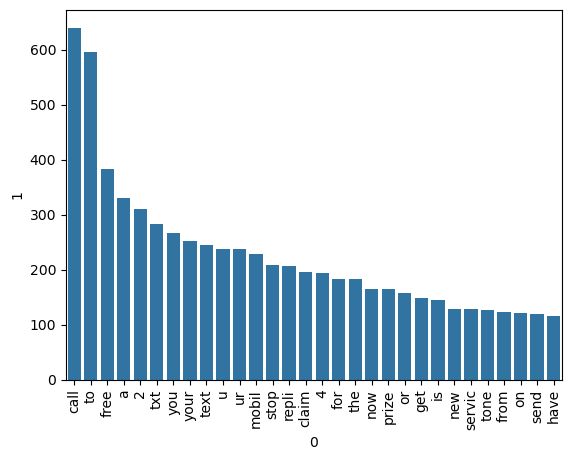

In [28]:
import seaborn as sns
from collections import Counter
topwords = pd.DataFrame(Counter(spam_corpus).most_common(30))
sns.barplot(
    x=topwords[0], 
    y=topwords[1]
)
plt.xticks(rotation='vertical')
plt.show()

In [29]:
#Model Building

from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
cv = CountVectorizer()
tfidf = TfidfVectorizer(max_features=3000)

X = tfidf.fit_transform(df['transformed_text']).toarray()

X.shape

(5169, 3000)

In [30]:
Y = df['target'].values

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.2, random_state=2)

In [32]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, precision_score, confusion_matrix

gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()

#GaussianNB ----------------
print("=========  GaussianNB  =========")
gnb.fit(X_train,Y_train)
y_pred1 = gnb.predict(X_test)
print(accuracy_score(Y_test,y_pred1))
print(confusion_matrix(Y_test,y_pred1))
print(precision_score(Y_test,y_pred1))
print("================================\n")

#MultinomialNB ----------------
print("=========  MultinomialNB  =========")
mnb.fit(X_train,Y_train)
y_pred1 = mnb.predict(X_test)
print(accuracy_score(Y_test,y_pred1))
print(confusion_matrix(Y_test,y_pred1))
print(precision_score(Y_test,y_pred1))
print("===================================\n")

#BernoulliNB ----------------
print("=========  BernoulliNB  =========")
bnb.fit(X_train,Y_train)
y_pred1 = bnb.predict(X_test)
print(accuracy_score(Y_test,y_pred1))
print(confusion_matrix(Y_test,y_pred1))
print(precision_score(Y_test,y_pred1))
print("=================================\n")



=========  GaussianNB  =========
0.8800773694390716
[[796 100]
 [ 24 114]]
0.5327102803738317

=========  MultinomialNB  =========
0.97678916827853
[[896   0]
 [ 24 114]]
1.0

=========  BernoulliNB  =========
0.9835589941972921
[[893   3]
 [ 14 124]]
0.9763779527559056



In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier


#creating the models
svc = SVC(kernel='sigmoid',gamma = 1.0)
knc = KNeighborsClassifier()
mnb = MultinomialNB()
dtc = DecisionTreeClassifier(max_depth=5)
lrc = LogisticRegression(solver='liblinear',penalty='l1')
rfc = RandomForestClassifier(n_estimators=50,random_state=2)
abc = AdaBoostClassifier(n_estimators=50,random_state=2)
bc = BaggingClassifier(n_estimators=50,random_state=2)
etc = ExtraTreesClassifier(n_estimators=50,random_state=2)
gbdt = GradientBoostingClassifier(n_estimators=50,random_state=2)
xgb = XGBClassifier(n_estimators=50,random_state=2)

clfs = {
    'SVC':svc,
    'KN':knc,
    'MNB':mnb,
    'DT':dtc,
    'LR':lrc,
    'RF':rfc,
    'AdaBoost':abc,
    'BgC':bc,
    'ETC':etc,
    'GBDT':gbdt,
    'XGB':xgb
}

#function to train the classifier
def train_classifier(clf,X_train,X_test,Y_train,Y_test):
    clf.fit(X_train,Y_train)
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(Y_test,y_pred)
    precision = precision_score(Y_test,y_pred)

    return accuracy,precision

accuracy_scores = []
precision_scores = []

for name,clf in clfs.items():
    current_acc,current_prec = train_classifier(clf,X_train,X_test,Y_train,Y_test)

    print("======================================")
    print("For ",name)
    print("Accuracy : ",current_acc)
    print("Precision : ",current_prec)
    print("======================================\n")

    accuracy_scores.append(current_acc)
    precision_scores.append(current_prec)

#lets create a dataframe for performance
perf_df = pd.DataFrame({'Alogrithm':clfs.keys(),'Accuracy':accuracy_scores,'Precision':precision_scores}).sort_values('Precision',ascending=False)

For  SVC
Accuracy :  0.9806576402321083
Precision :  0.9836065573770492

For  KN
Accuracy :  0.90715667311412
Precision :  1.0

For  MNB
Accuracy :  0.97678916827853
Precision :  1.0

For  DT
Accuracy :  0.9381044487427466
Precision :  0.87

For  LR
Accuracy :  0.9584139264990329
Precision :  0.9439252336448598

For  RF
Accuracy :  0.9709864603481625
Precision :  0.9821428571428571

For  AdaBoost
Accuracy :  0.9429400386847195
Precision :  0.9540229885057471

For  BgC
Accuracy :  0.9671179883945842
Precision :  0.8939393939393939

For  ETC
Accuracy :  0.9787234042553191
Precision :  0.9833333333333333

For  GBDT
Accuracy :  0.9574468085106383
Precision :  0.97

For  XGB
Accuracy :  0.9787234042553191
Precision :  0.967741935483871



In [40]:
#lets create a dataframe for performance
perf_df = pd.DataFrame({'Alogrithm':clfs.keys(),'Accuracy':accuracy_scores,'Precision':precision_scores}).sort_values('Precision',ascending=False)
perf_df

,Alogrithm,Accuracy,Precision
1,KN,0.907157,1.000000
2,MNB,0.976789,1.000000
0,SVC,0.980658,0.983607
8,ETC,0.978723,0.983333
5,RF,0.970986,0.982143
9,GBDT,0.957447,0.970000
10,XGB,0.978723,0.967742
6,AdaBoost,0.942940,0.954023
4,LR,0.958414,0.943925
7,BgC,0.967118,0.893939


In [41]:
perf_df1 = pd.melt(perf_df,id_vars="Alogrithm")
perf_df1

,Alogrithm,variable,value
0,KN,Accuracy,0.907157
1,MNB,Accuracy,0.976789
2,SVC,Accuracy,0.980658
3,ETC,Accuracy,0.978723
4,RF,Accuracy,0.970986
5,GBDT,Accuracy,0.957447
6,XGB,Accuracy,0.978723
7,AdaBoost,Accuracy,0.942940
8,LR,Accuracy,0.958414
9,BgC,Accuracy,0.967118


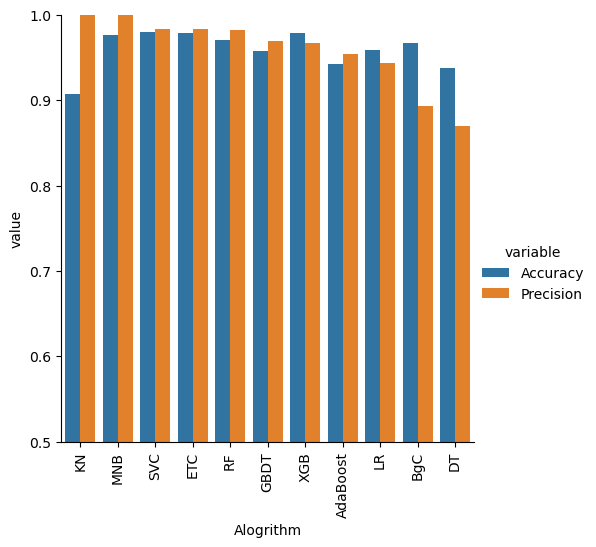

In [43]:
sns.catplot(x = 'Alogrithm', y= 'value', hue = 'variable', data = perf_df1, kind = 'bar', height = 5)
plt.ylim(0.5,1.0)
plt.xticks(rotation = 'vertical')
plt.show()

In [45]:
#temp df

temp_df = pd.DataFrame({'Alogrithm':clfs.keys(),'Accuracy_max_ft_3000':accuracy_scores,'Precision_max_ft_3000':precision_scores}).sort_values('Precision_max_ft_3000',ascending=False)
new_df = perf_df.merge(temp_df, on='Alogrithm')

new_df.head()



,Alogrithm,Accuracy,Precision,Accuracy_max_ft_3000,Precision_max_ft_3000
0,KN,0.907157,1.000000,0.907157,1.000000
1,MNB,0.976789,1.000000,0.976789,1.000000
2,SVC,0.980658,0.983607,0.980658,0.983607
3,ETC,0.978723,0.983333,0.978723,0.983333
4,RF,0.970986,0.982143,0.970986,0.982143


In [46]:
temp_df = pd.DataFrame({'Alogrithm':clfs.keys(),'Accuracy_scaling':accuracy_scores,'Precision_scaling':precision_scores}).sort_values('Precision_scaling',ascending=False)
new_df_scaled= perf_df.merge(temp_df, on='Alogrithm')
new_df_scaled.head()

,Alogrithm,Accuracy,Precision,Accuracy_scaling,Precision_scaling
0,KN,0.907157,1.000000,0.907157,1.000000
1,MNB,0.976789,1.000000,0.976789,1.000000
2,SVC,0.980658,0.983607,0.980658,0.983607
3,ETC,0.978723,0.983333,0.978723,0.983333
4,RF,0.970986,0.982143,0.970986,0.982143


In [50]:
#Voting Classifier
svc = SVC(kernel='sigmoid',gamma = 1.0, probability=True)
mnb = MultinomialNB()
etc = ExtraTreesClassifier(n_estimators=50,random_state=2)

from sklearn.ensemble import VotingClassifier

voting = VotingClassifier(estimators=[('svm',svc),('mnb',mnb),('etc',etc)],voting='soft')
voting.fit(X_train,Y_train)

VotingClassifier(estimators=[('svm',
                              SVC(gamma=1.0, kernel='sigmoid',
                                  probability=True)),
                             ('mnb', MultinomialNB()),
                             ('etc',
                              ExtraTreesClassifier(n_estimators=50,
                                                   random_state=2))],
                 voting='soft')

In [51]:
y_pred = voting.predict(X_test)
print("Accuracy",accuracy_score(Y_test,y_pred))
print("Precision",precision_score(Y_test,y_pred))

Accuracy 0.9835589941972921
Precision 0.991869918699187


In [52]:
#applying stacking
estimators=[('svm',svc),('mnb',mnb),('etc',etc)]
final_estimator = RandomForestClassifier()

from sklearn.ensemble import StackingClassifier

clf = StackingClassifier(estimators=estimators, final_estimator=final_estimator)

clf.fit(X_train,Y_train)
y_pred = clf.predict(X_test)
print("Accuracy",accuracy_score(Y_test,y_pred))
print("Precision",precision_score(Y_test,y_pred))

Accuracy 0.9854932301740812
Precision 0.9694656488549618


In [53]:
import pickle
pickle.dump(tfidf,open('vectorizer.pkl','wb'))
pickle.dump(mnb,open('model.pkl','wb'))